In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df_com_restricao = pd.read_csv('/content/df_merge_com_restricao.csv')
df_sem_restricao = pd.read_csv('/content/df_merge_sem_restricao.csv')

In [ ]:
df_com_restricao.head()

,data_hora_utc,geracao_alvo_mwmed,alvo_referencia_ons,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
0,2025-01-01 00:00:00,0.0,0,26.2,69.0,965.1,0.0,0.000000
1,2025-01-01 01:00:00,0.0,0,25.1,71.0,965.7,0.0,0.000000
2,2025-01-01 02:00:00,0.0,0,25.2,70.0,966.4,0.0,0.016689
3,2025-01-01 03:00:00,0.0,0,25.2,71.0,966.4,0.0,0.055790
4,2025-01-01 04:00:00,0.0,0,24.4,78.0,966.1,0.0,0.017643


In [ ]:
df_sem_restricao.head()

,data_hora_utc,geracao_mwmed,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
0,2025-01-01 00:00:00,0.0,26.2,69.0,965.1,0.0,0.000000
1,2025-01-01 01:00:00,0.0,25.1,71.0,965.7,0.0,0.000000
2,2025-01-01 02:00:00,0.0,25.2,70.0,966.4,0.0,0.016689
3,2025-01-01 03:00:00,0.0,25.2,71.0,966.4,0.0,0.055790
4,2025-01-01 04:00:00,0.0,24.4,78.0,966.1,0.0,0.017643


In [ ]:
df_sem_restricao['data_hora_utc'] = pd.to_datetime(df_sem_restricao['data_hora_utc'])
df_com_restricao['data_hora_utc'] = pd.to_datetime(df_com_restricao['data_hora_utc'])

In [ ]:
df_sem_restricao.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7035 entries, 0 to 7034
Data columns (total 7 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   data_hora_utc                                         7035 non-null   datetime64[ns]
 1   geracao_mwmed                                         7035 non-null   float64       
 2   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           7035 non-null   float64       
 3   UMIDADE RELATIVA DO AR, HORARIA(%)                    7035 non-null   float64       
 4   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)  7035 non-null   float64       
 5   Radiação (Wh/m2)                                      7035 non-null   float64       
 6   PRECIPITACAO ERA5, HORARIA(mm)                        7035 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 384.9 KB


In [ ]:
df_com_restricao.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 8 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   data_hora_utc                                         8760 non-null   datetime64[ns]
 1   geracao_alvo_mwmed                                    8760 non-null   float64       
 2   alvo_referencia_ons                                   8760 non-null   int64         
 3   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           8760 non-null   float64       
 4   UMIDADE RELATIVA DO AR, HORARIA(%)                    8760 non-null   float64       
 5   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)  8760 non-null   float64       
 6   Radiação (Wh/m2)                                      8760 non-null   float64       
 7   PRECIPITACAO ERA5, HORARIA(mm)                        8760 non-null   float64  

In [ ]:
df_com_restricao.drop('alvo_referencia_ons', axis=1, inplace=True)

* **df_sem_restricao**: somente geração observada em períodos sem constrained-off;
* **df_com_referencia**: série completa, usando referência do ONS quando houve constrained-off.

## 1.3 Estatística descritiva

Análise meteorológica detalhada em um dataset base, porque temperatura, umidade, pressão, radiação e precipitação são as mesmas séries

In [ ]:
cols_meteo = [
    'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)',
    'UMIDADE RELATIVA DO AR, HORARIA(%)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)',
    'Radiação (Wh/m2)',
    'PRECIPITACAO ERA5, HORARIA(mm)'
]

In [ ]:
estatisticas_meteo = (
    df_com_restricao[cols_meteo]
    .describe()
    .T
    [['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
)

estatisticas_meteo

,mean,std,min,25%,50%,75%,max
"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",24.148423,5.393201,4.3,20.800000,23.90000,27.700000,39.512918
"UMIDADE RELATIVA DO AR, HORARIA(%)",65.606141,21.164257,11.0,49.046585,66.00000,82.000000,100.000000
"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",970.542586,3.812099,958.9,967.800000,970.30000,973.200000,982.300000
Radiação (Wh/m2),229.594089,320.188190,0.0,0.000000,6.85455,442.976250,1128.223900
"PRECIPITACAO ERA5, HORARIA(mm)",0.092250,0.451351,0.0,0.000000,0.00000,0.000954,14.488697


In [ ]:
comparacao_geracao = pd.DataFrame({
    'sem_restricao': df_sem_restricao['geracao_mwmed'].describe(),
    'com_restricao': df_com_restricao['geracao_alvo_mwmed'].describe()
})
comparacao_geracao

,sem_restricao,com_restricao
count,7035.000000,8760.000000
mean,11.459798,16.729962
std,20.264550,22.609223
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.282500
75%,11.847500,36.020000
max,71.426000,73.182000


## 1.4 Distribuições

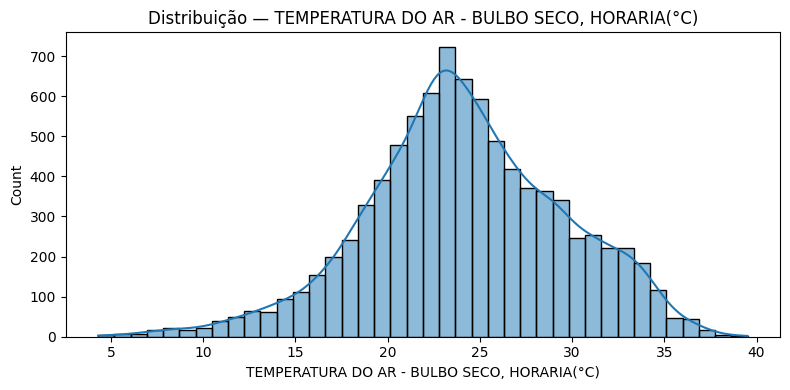

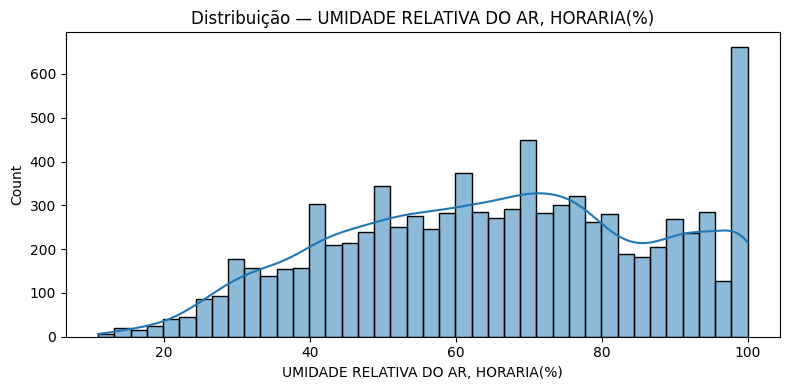

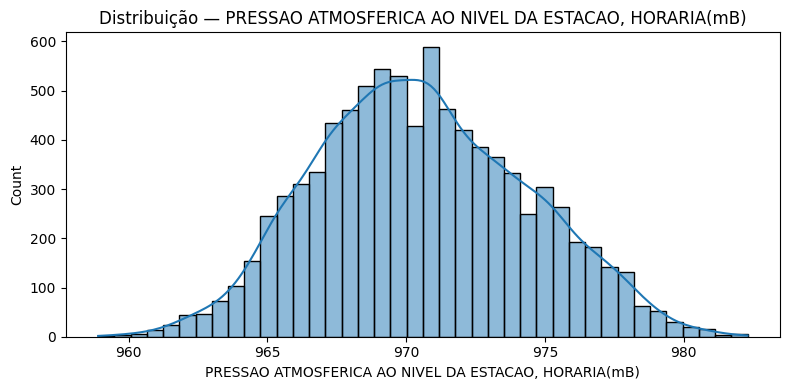

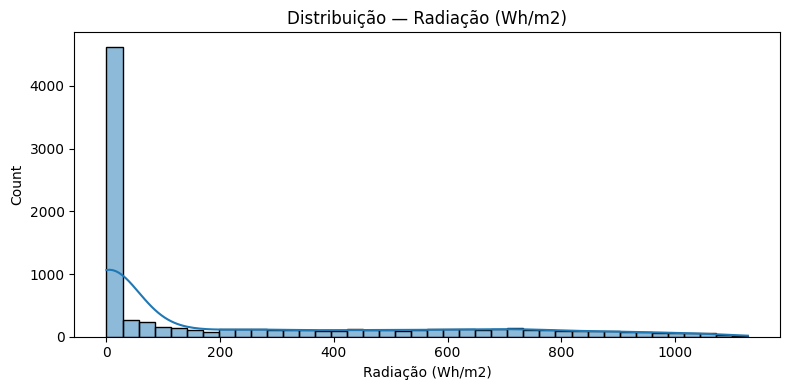

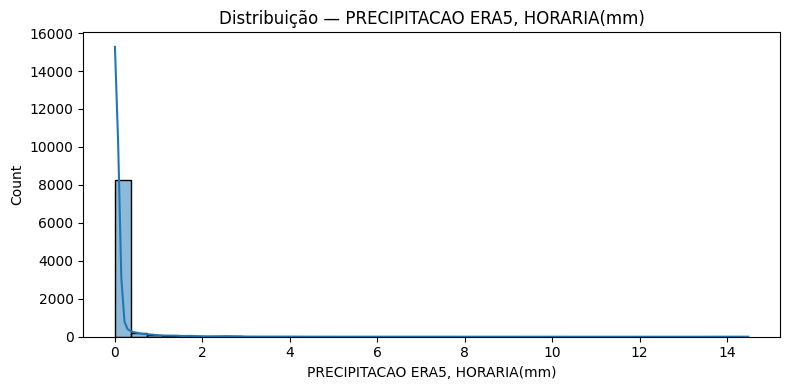

In [ ]:
for col in cols_meteo:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df_com_restricao,
        x=col,
        bins=40,
        kde=True
    )

    plt.title(f'Distribuição — {col}')
    plt.tight_layout()
    plt.show()

Precipitação: Muito tempo sem chuva, uma região que não chove tanto. Ou uma seca incomum para esse ano?    
Radiação: muitas horas noturnas o que puxa a distribuição concentrando em zero

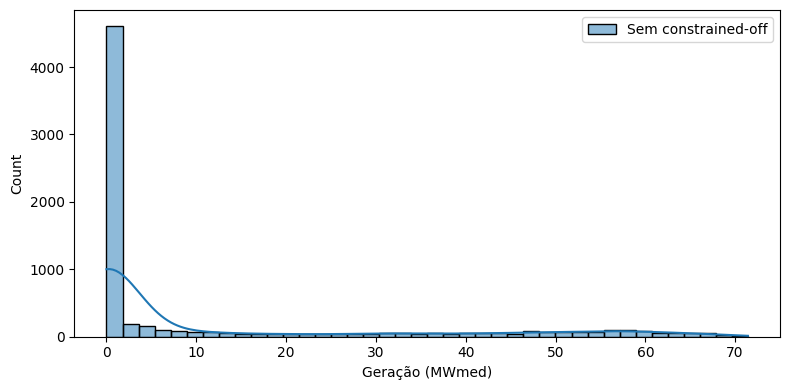

In [ ]:
plt.figure(figsize=(8, 4))

sns.histplot(
    df_sem_restricao['geracao_mwmed'],
    bins=40,
    kde=True,
    label='Sem constrained-off',
    alpha=0.5
)

plt.xlabel('Geração (MWmed)')
plt.legend()
plt.tight_layout()
plt.show()

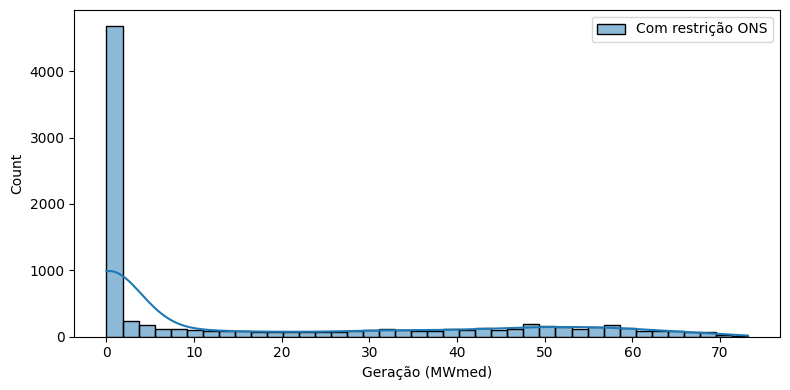

In [ ]:
plt.figure(figsize=(8, 4))

sns.histplot(
    df_com_restricao['geracao_alvo_mwmed'],
    bins=40,
    kde=True,
    label='Com restrição ONS',
    alpha=0.5
)
plt.xlabel('Geração (MWmed)')
plt.legend()
plt.tight_layout()
plt.show()

Radiação, Precipitação e Geração são distribuições exponenciais. Muito semelhante ao gráfico 4.7 do Guide to Climatological Practices 2018ed

Figura 4.7. Distribuição exponencial: descreve os intervalos de tempo entre eventos em um processo no qual os eventos ocorrem de forma contínua e independente a uma taxa média constante. Ela tem sido utilizada
em análises de volumes de precipitação diária.  

ou a Figura 4.11. Distribuição gama: descreve distribuições limitadas em uma extremidade e assimétricas, como dados de precipitação.

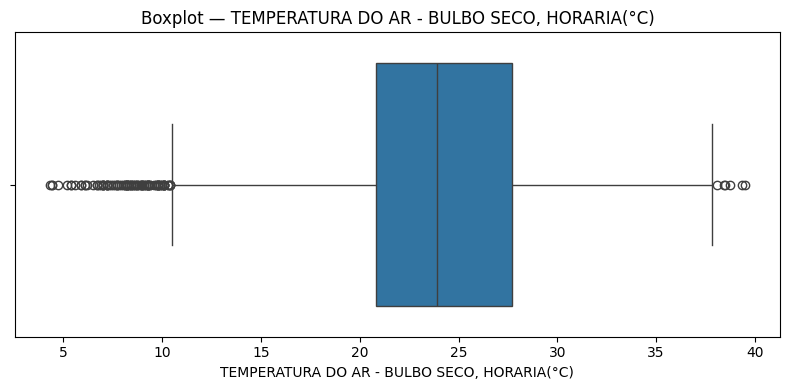

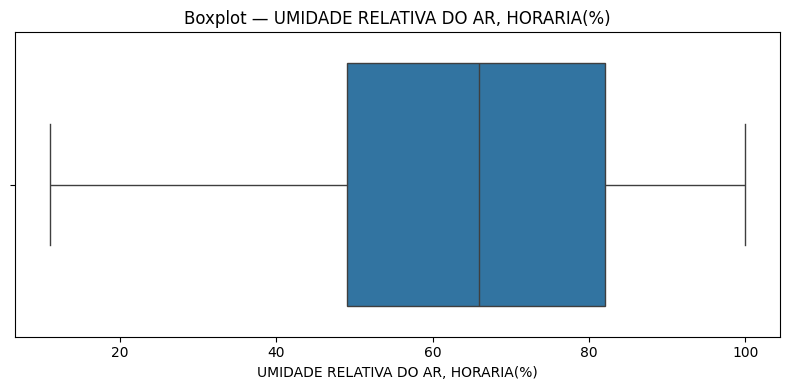

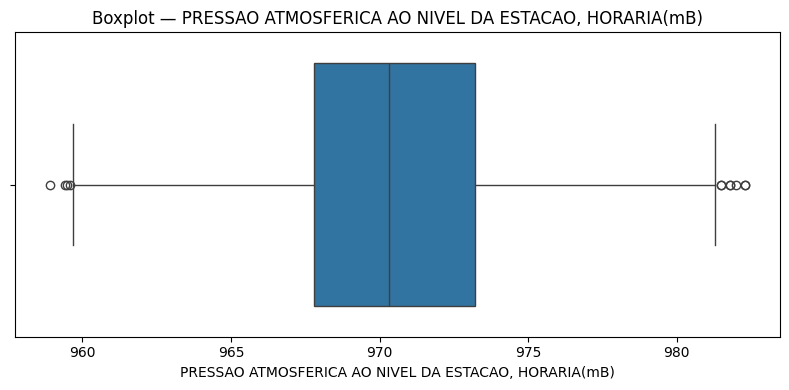

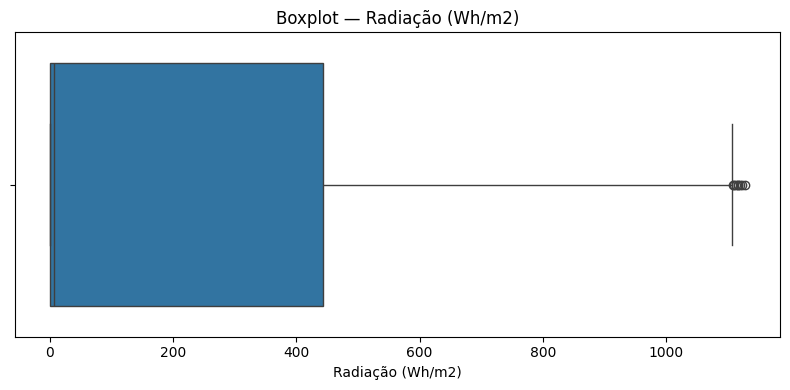

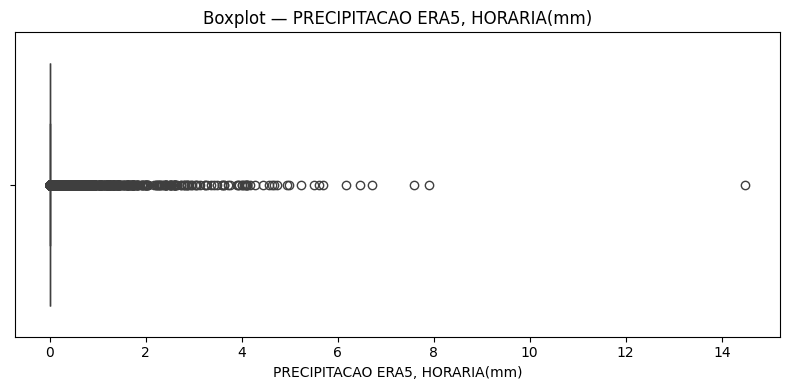

In [ ]:
for col in cols_meteo:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df_com_restricao,
        x=col
    )

    plt.title(f'Boxplot — {col}')
    plt.tight_layout()
    plt.show()

In [ ]:
df_eda = df_sem_restricao.copy()

df_eda['mes'] = df_eda['data_hora_utc'].dt.month
df_eda['hora'] = df_eda['data_hora_utc'].dt.hour

In [ ]:
df_eda_comr = df_com_restricao.copy()

df_eda_comr['mes'] = df_eda_comr['data_hora_utc'].dt.month
df_eda_comr['hora'] = df_eda_comr['data_hora_utc'].dt.hour

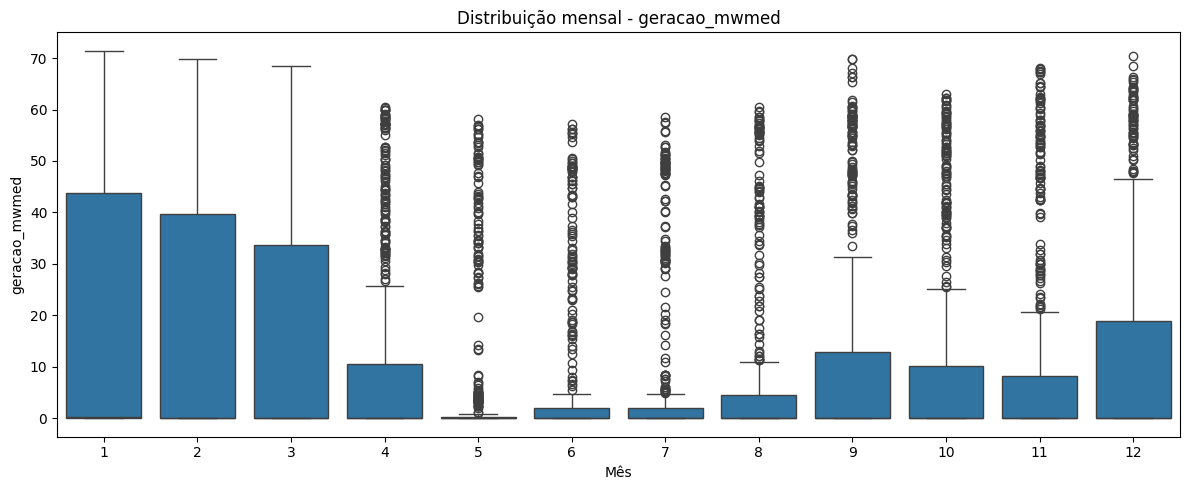

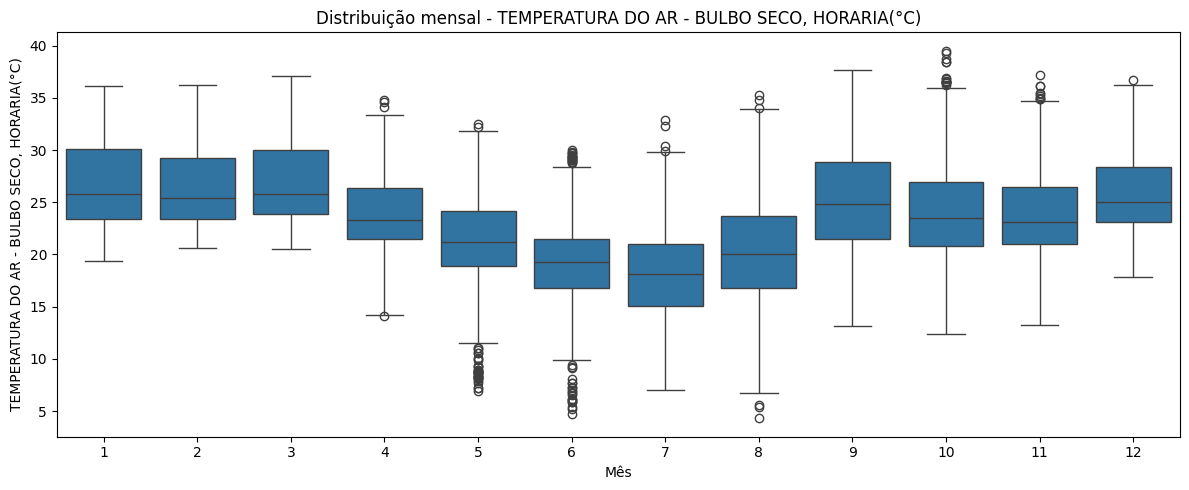

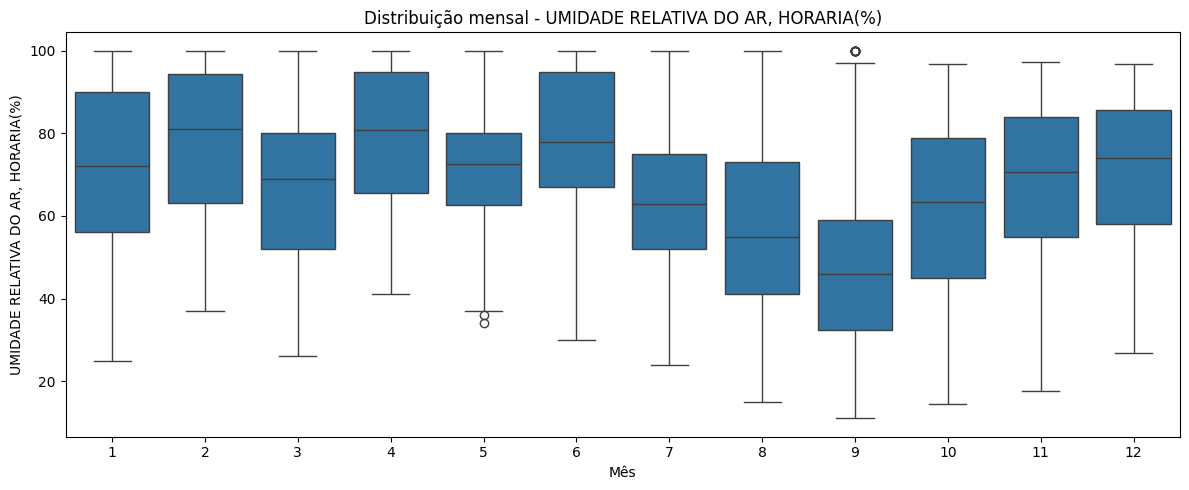

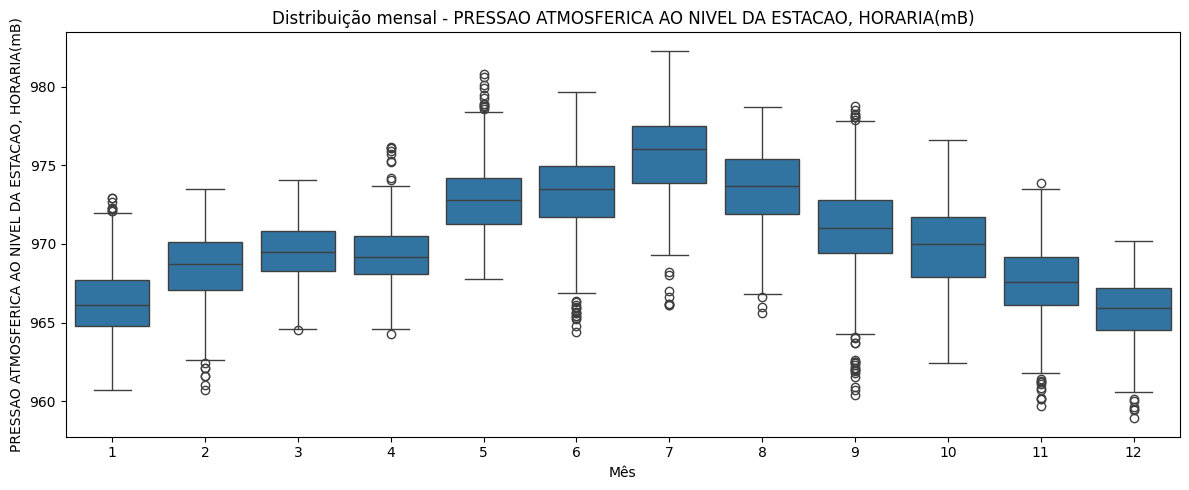

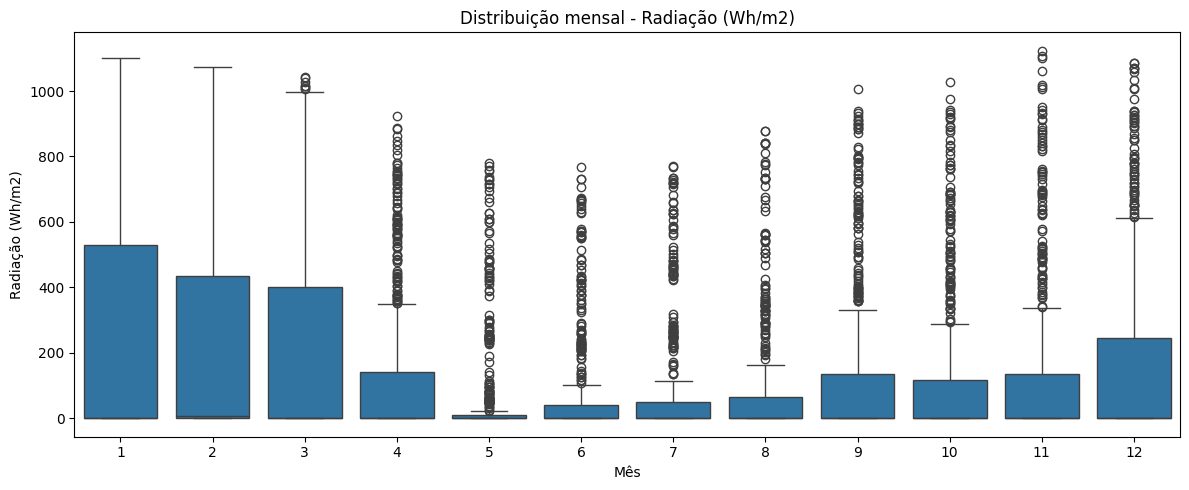

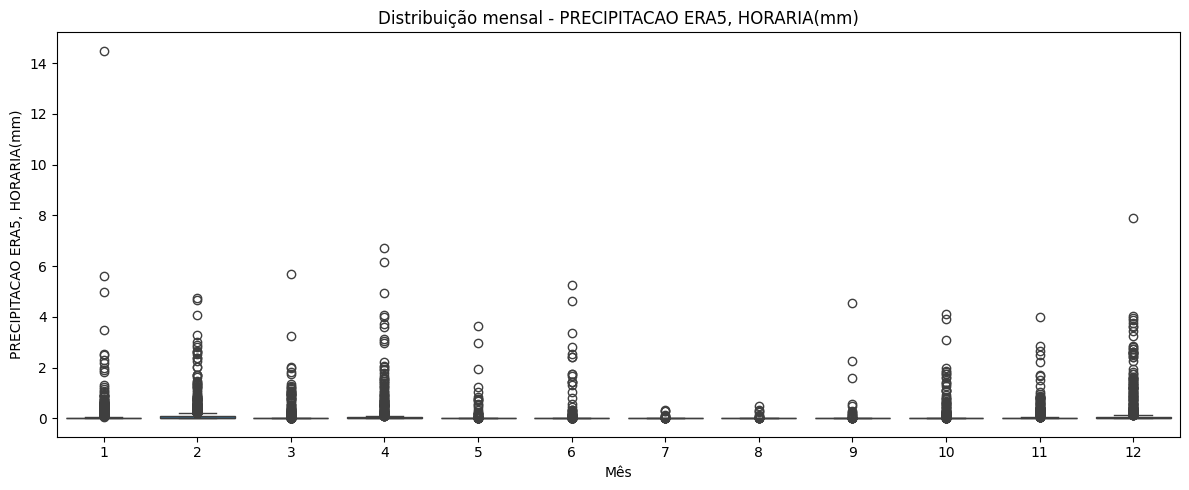

In [ ]:
for col in ['geracao_mwmed'] + cols_meteo:
    plt.figure(figsize=(12, 5))

    sns.boxplot(
        data=df_eda,
        x='mes',
        y=col
    )

    plt.title(f'Distribuição mensal - {col}')
    plt.xlabel('Mês')
    plt.tight_layout()
    plt.show()

Df sem restrição apresenta uma queda brusca na geração entre Abril e Agosto, isso pode representar o efeito da remoção dos dados, o que pode levar a conclusões falsas pelo modelo. O modelo pode entender que isso seria algo sazonal. Já no Df com restrição que foi reconstruido a partir dos valores previstos pela ONS essa queda entre Abril e Agosto não é percebida.

Text(0.5, 0, 'Hora UTC')

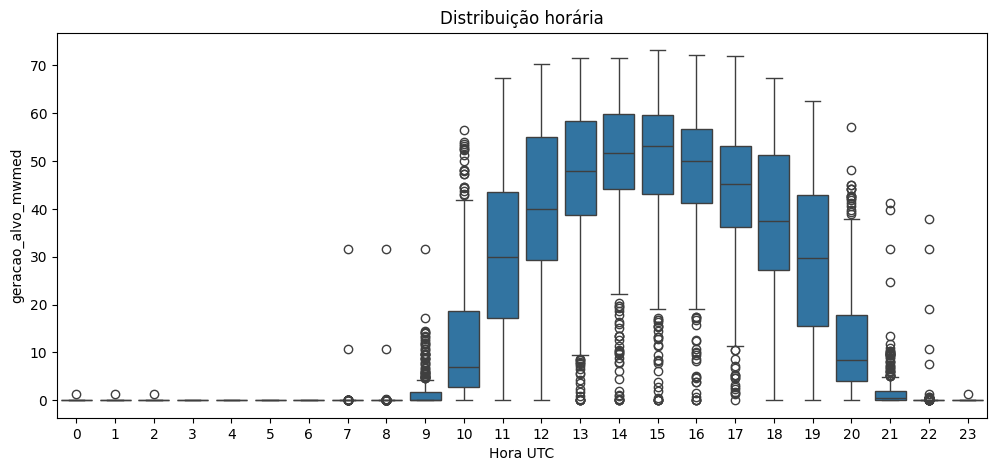

In [ ]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df_eda_comr,
    x='hora',
    y='geracao_alvo_mwmed'
)

plt.title('Distribuição horária')
plt.xlabel('Hora UTC')

Text(0.5, 0, 'Mes')

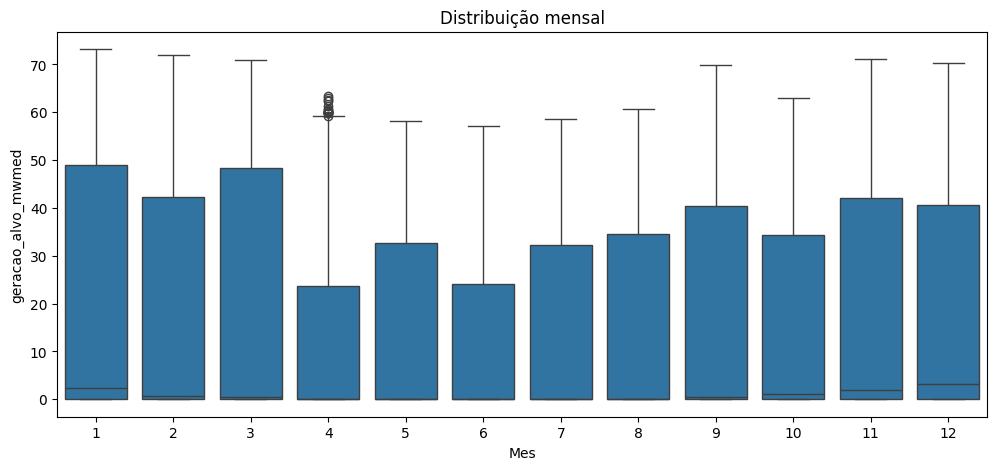

In [ ]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df_eda_comr,
    x='mes',
    y='geracao_alvo_mwmed'
)

plt.title('Distribuição mensal')
plt.xlabel('Mes')

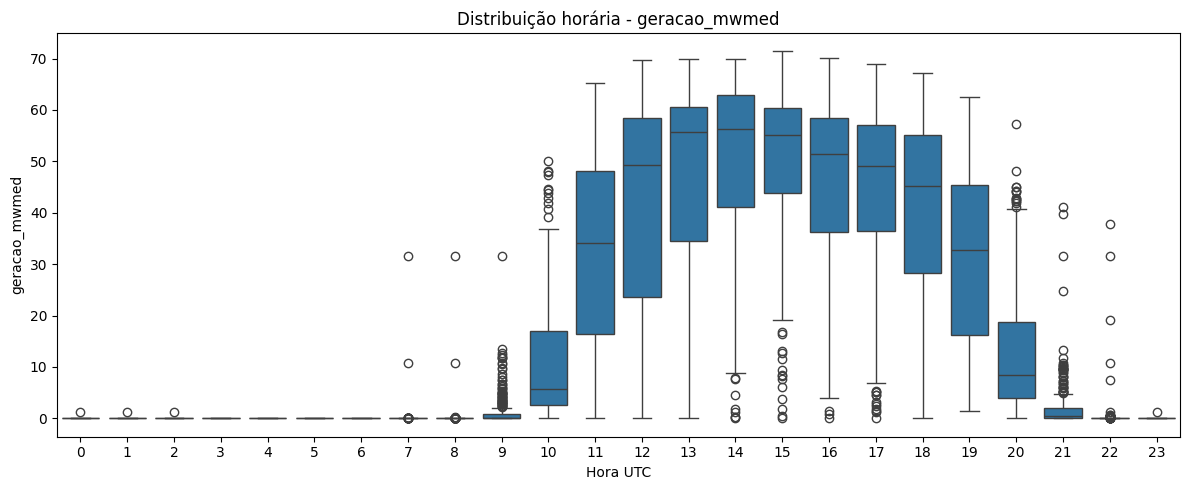

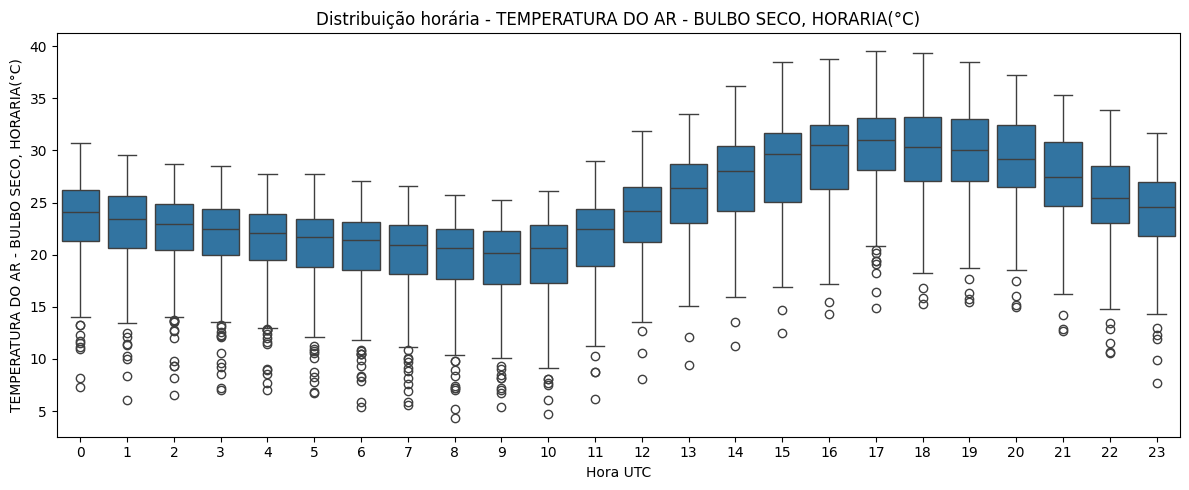

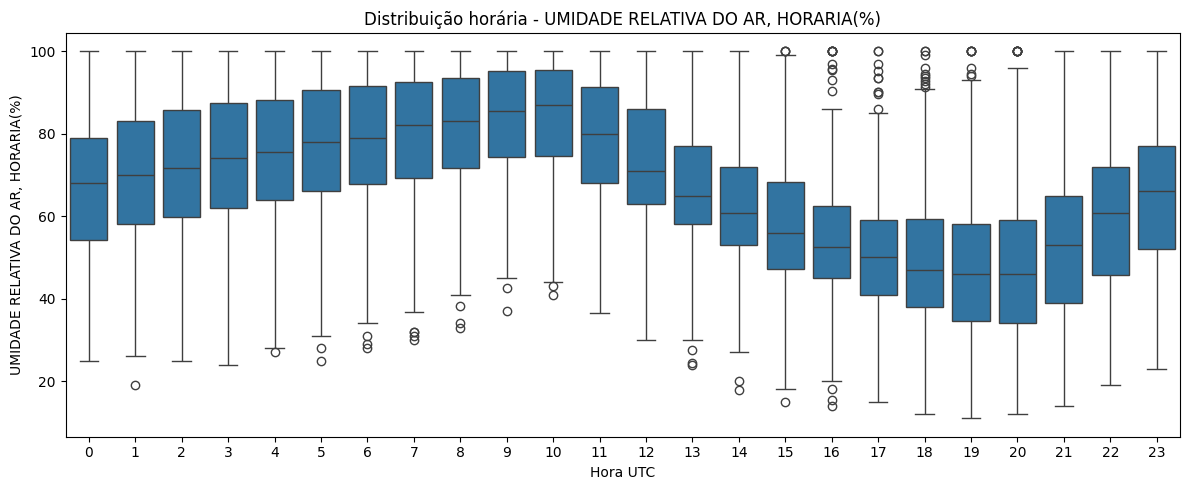

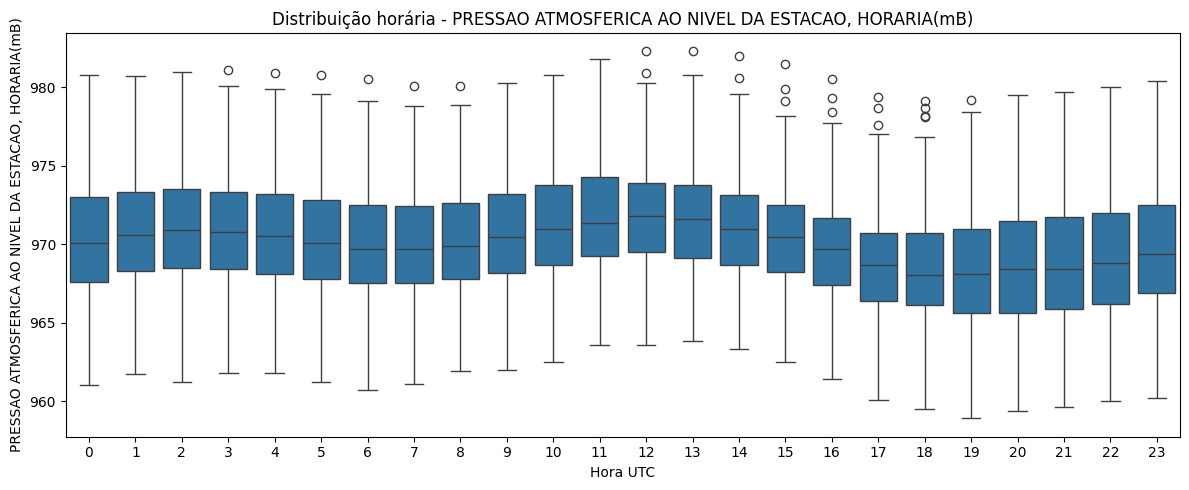

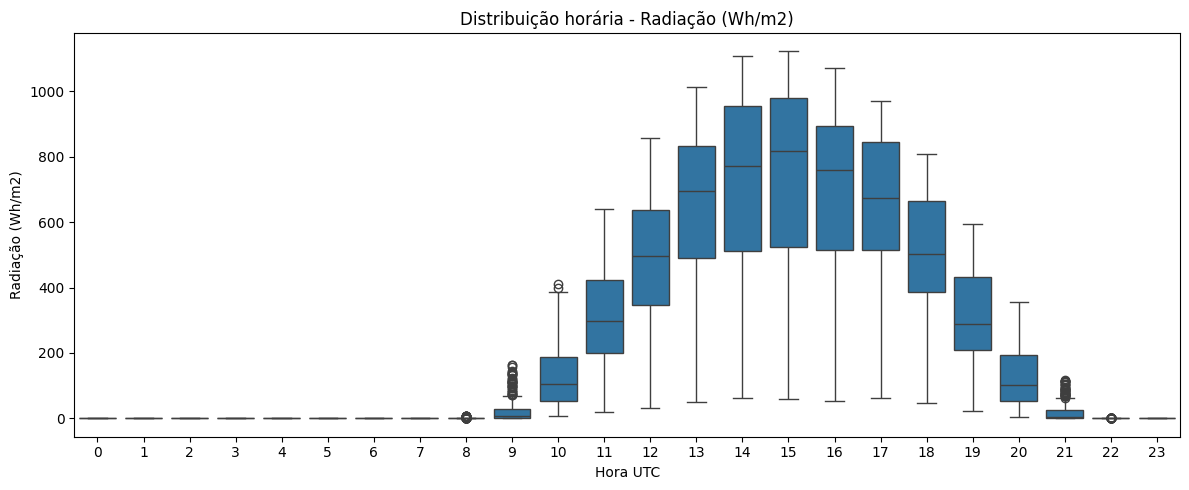

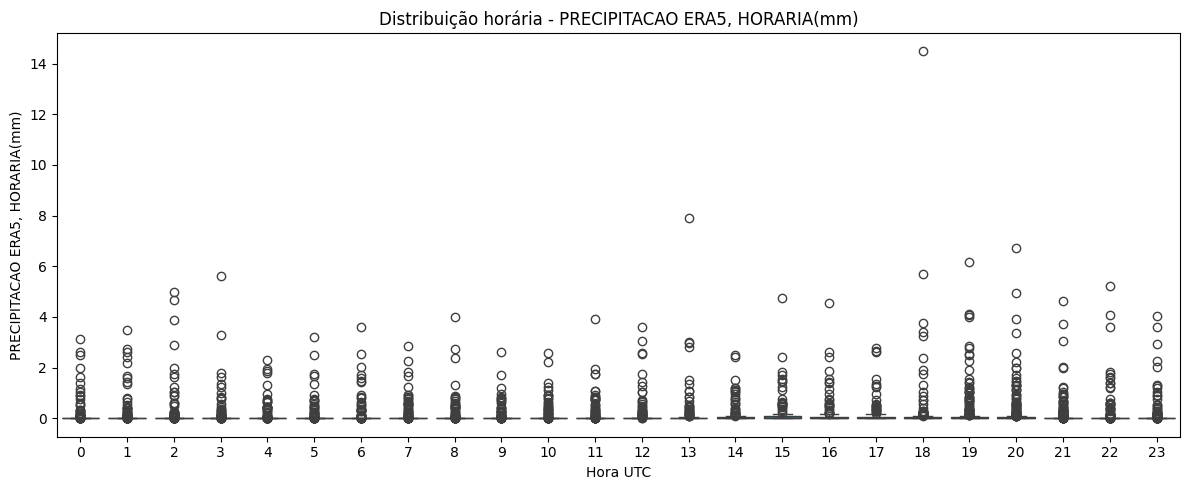

In [ ]:
for col in ['geracao_mwmed'] + cols_meteo:
    plt.figure(figsize=(12, 5))

    sns.boxplot(
        data=df_eda,
        x='hora',
        y=col
    )

    plt.title(f'Distribuição horária - {col}')
    plt.xlabel('Hora UTC')
    plt.tight_layout()
    plt.show()

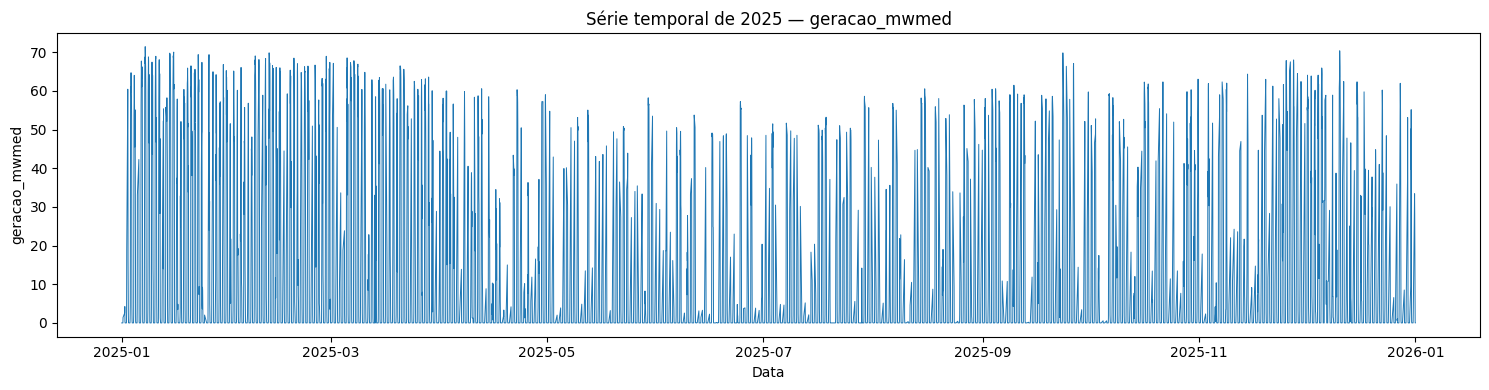

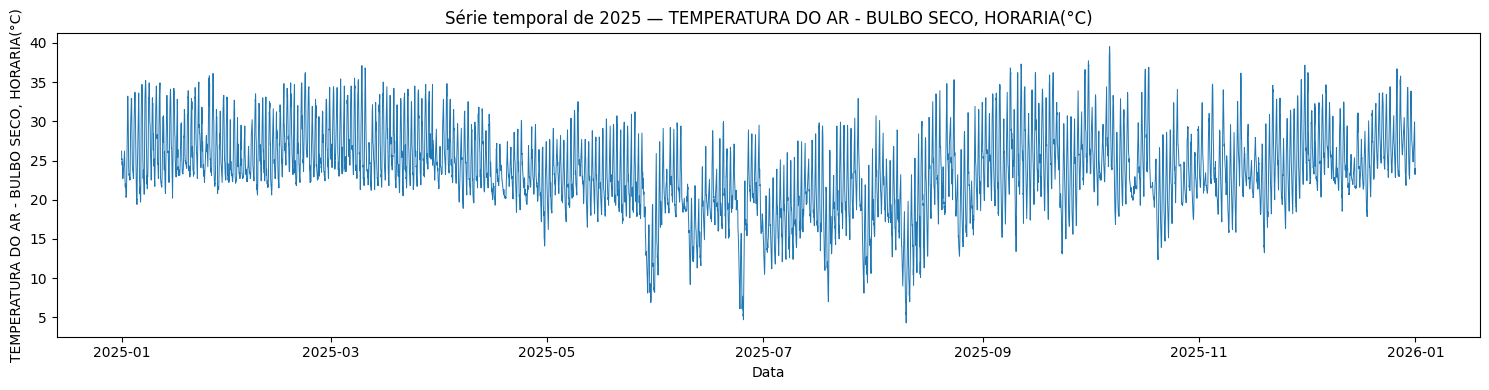

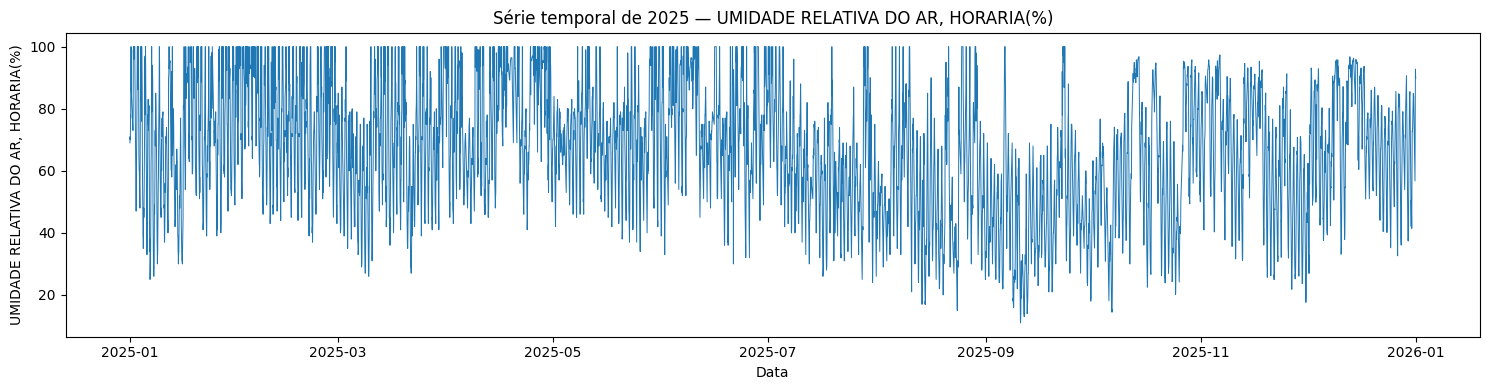

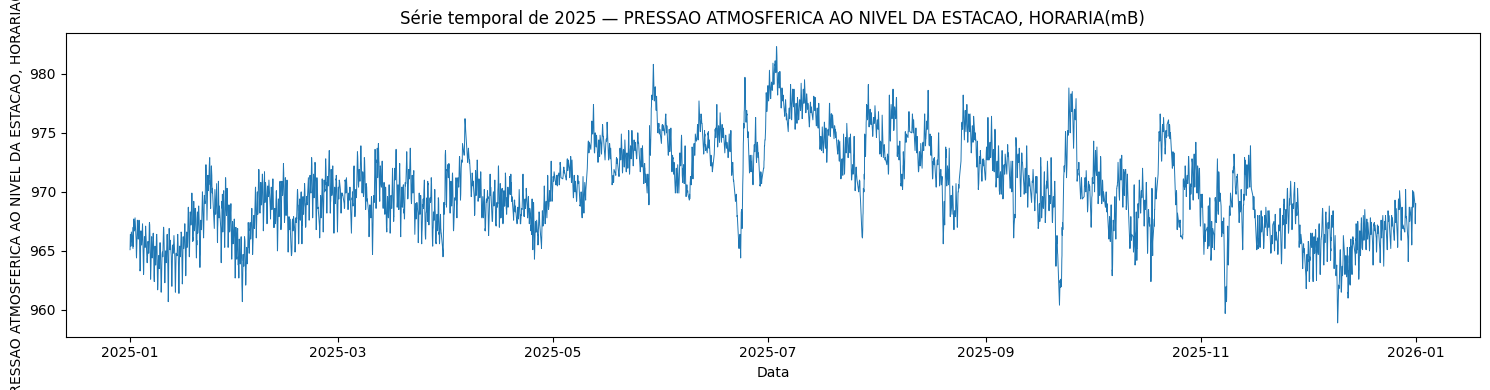

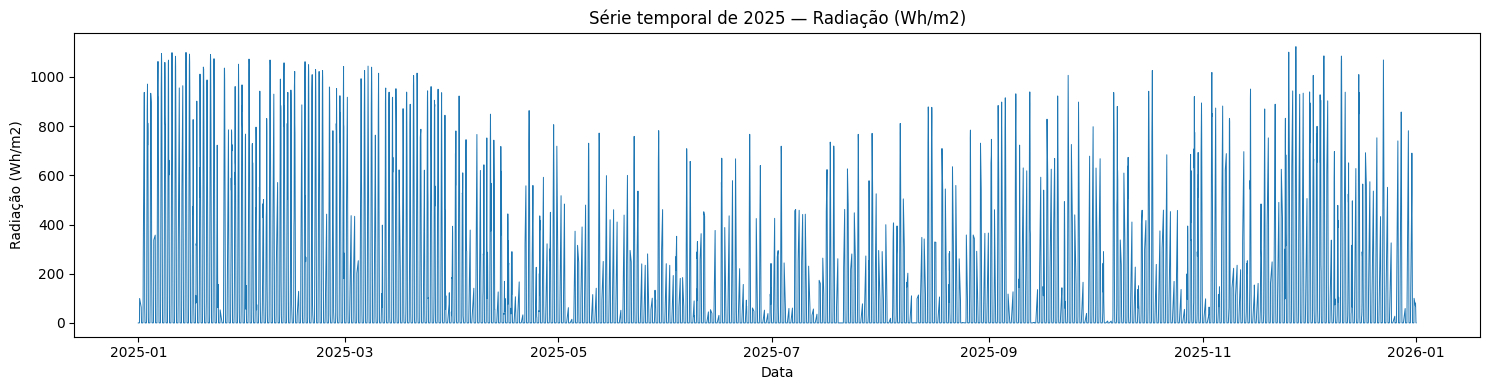

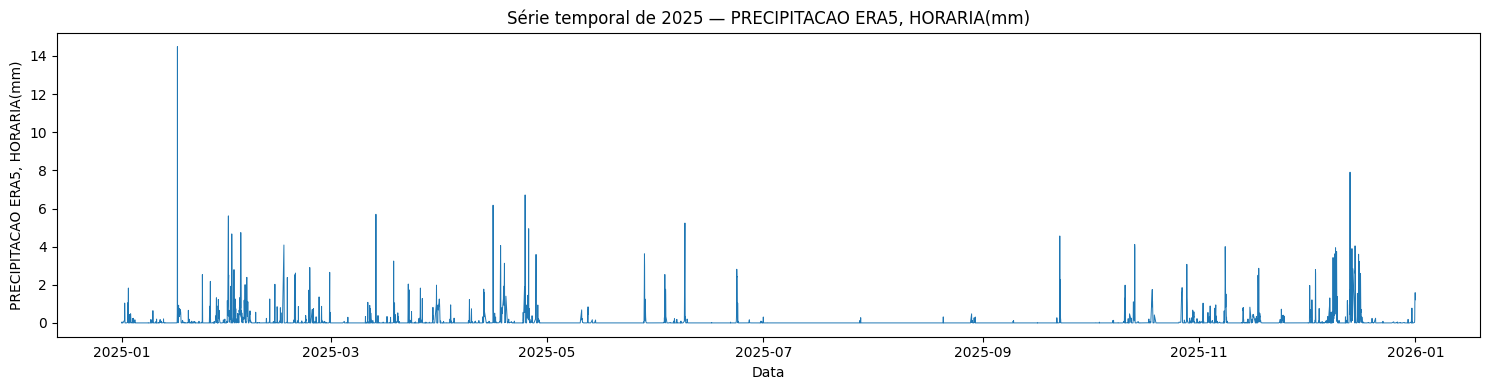

In [ ]:
for col in ['geracao_mwmed'] + cols_meteo:
    plt.figure(figsize=(15, 4))

    plt.plot(
        df_eda['data_hora_utc'],
        df_eda[col],
        linewidth=0.7
    )

    plt.title(f'Série temporal de 2025 — {col}')
    plt.xlabel('Data')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

A partir da análise dos gráficos, distribuição horária, mensal e anual é possível observar certa coerência nos dados, portanto o alinhamento temporal feito no notebook 01 está correto e os dados meteorológicos apesar de feita a junção com fontes e locais diferentes apresentam um padrão esperado para a localidade. Com essa analise gráfica consigo avaliar os outliers dos dados, entretanto, preciso verificar se isso é um evento correto que é possível ter ocorrido, ou se o dado foi registrado incorretamente.

## Anomalias

Para tratar e investigar anomalias vou usar como base as informações fornecidas pelo WMo nesse guia: https://dgm-meteo.github.io/wmo-clino/Docs/WMO2018_100_en_Guide%20to%20Climatological%20Practices.pdf

Com restrição

In [ ]:
from scipy import stats
iqr_scripy = stats.iqr(df_com_restricao['geracao_alvo_mwmed'])
print(iqr_scripy)

36.02


In [ ]:
resultados_cr = []
q1_cr = df_com_restricao['geracao_alvo_mwmed'].quantile(0.25)
q3_cr = df_com_restricao['geracao_alvo_mwmed'].quantile(0.75)
iqr_cr = q3_cr - q1_cr
limite_inferior_cr = q1_cr - 1.5 * iqr_cr
limite_superior_cr = q3_cr + 1.5 * iqr_cr
outliers_cr = df_com_restricao[
  (df_com_restricao['geracao_alvo_mwmed'] < limite_inferior_cr) |
  (df_com_restricao['geracao_alvo_mwmed'] > limite_superior_cr)
]
resultados_cr.append({
  'variavel': 'geracao_alvo_mwmed',
  'Q1': q1_cr,
  'Q3': q3_cr,
  'IQR': iqr_cr,
  'limite_inferior': limite_inferior_cr,
  'limite_superior': limite_superior_cr,
  'n_sinalizados': len(outliers_cr),
  'percentual': len(outliers_cr) / len(df_com_restricao) * 100
})

In [ ]:
for coluna in cols_meteo:
    q1 = df_com_restricao[coluna].quantile(0.25)
    q3 = df_com_restricao[coluna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = df_com_restricao[
        (df_com_restricao[coluna] < limite_inferior) |
        (df_com_restricao[coluna] > limite_superior)
    ]

    resultados_cr.append({
        'variavel': coluna,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'limite_inferior': limite_inferior,
        'limite_superior': limite_superior,
        'n_sinalizados': len(outliers),
        'percentual': len(outliers) / len(df_com_restricao) * 100
    })

resultado_iqr = pd.DataFrame(resultados_cr)

resultado_iqr

,variavel,Q1,Q3,IQR,limite_inferior,limite_superior,n_sinalizados,percentual
0,geracao_alvo_mwmed,0.000000,36.020000,36.020000,-54.030000,90.050000,0,0.000000
1,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",20.800000,27.700000,6.900000,10.450000,38.050000,101,1.152968
2,"UMIDADE RELATIVA DO AR, HORARIA(%)",49.046585,82.000000,32.953415,-0.383538,131.430123,0,0.000000
3,"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORAR...",967.800000,973.200000,5.400000,959.700000,981.300000,11,0.125571
4,Radiação (Wh/m2),0.000000,442.976250,442.976250,-664.464375,1107.440625,8,0.091324
5,"PRECIPITACAO ERA5, HORARIA(mm)",0.000000,0.000954,0.000954,-0.001431,0.002384,2054,23.447489


Características climáticas de 2025 https://portal.inmet.gov.br/noticias/ano-de-2025-foi-o-s%C3%A9timo-mais-quente-no-brasil-desde-1961    
sétimo ano mais quente desde 1961    


Clima em Dracena: Tropical Semiúmido
Oeste Paulista

In [ ]:
temp_suspeitos = df_com_restricao[
    (df_com_restricao['TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)'] < 10.45) |
    (df_com_restricao['TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)'] > 38.05)
][[
    'data_hora_utc',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)'
]]

pressao_suspeitos = df_com_restricao[
    (df_com_restricao['PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)'] < 959.7) |
    (df_com_restricao['PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)'] > 981.3)
][[
    'data_hora_utc',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)'
]]

radiacao_suspeitos = df_com_restricao[
    df_com_restricao['Radiação (Wh/m2)'] > 1107.440625
][[
    'data_hora_utc',
    'Radiação (Wh/m2)'
]]

In [ ]:
print(df_com_restricao.loc[df_com_restricao['data_hora_utc'] == '2025-05-29 12:00:00', 'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)'])

3564    10.6
Name: TEMPERATURA DO AR - BULBO SECO, HORARIA(°C), dtype: float64


O IQR me mostra os valores elevados ou abaixo do esperado em relação a distribuição anual

In [ ]:
print(temp_suspeitos.to_markdown())

|      | data_hora_utc       |   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C) |
|-----:|:--------------------|----------------------------------------------:|
| 3559 | 2025-05-29 07:00:00 |                                       10.1    |
| 3560 | 2025-05-29 08:00:00 |                                        8.9    |
| 3561 | 2025-05-29 09:00:00 |                                        8.5    |
| 3562 | 2025-05-29 10:00:00 |                                        8.1    |
| 3563 | 2025-05-29 11:00:00 |                                        8.7    |
| 3575 | 2025-05-29 23:00:00 |                                        9.9    |
| 3576 | 2025-05-30 00:00:00 |                                        8.2    |
| 3577 | 2025-05-30 01:00:00 |                                        8.4    |
| 3578 | 2025-05-30 02:00:00 |                                        9.3    |
| 3579 | 2025-05-30 03:00:00 |                                        9.2    |
| 3580 | 2025-05-30 04:00:00 |                      

Os valores de temperatura parecem estar coerentes com o que foi registrado pelo INMET nessa época do ano, massa de ar frio nessa localidade

In [ ]:
pressao_suspeitos

,data_hora_utc,"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)"
4381,2025-07-02 13:00:00,981.5
4382,2025-07-02 14:00:00,981.8
4403,2025-07-03 11:00:00,981.8
4404,2025-07-03 12:00:00,982.3
4405,2025-07-03 13:00:00,982.3
4406,2025-07-03 14:00:00,982.0
4407,2025-07-03 15:00:00,981.5
8226,2025-12-09 18:00:00,959.5
8227,2025-12-09 19:00:00,958.9
8228,2025-12-09 20:00:00,959.4


GHI. Global irradiation on horizontal plane at ground level (Wh/m2)

In [ ]:
radiacao_suspeitos

,data_hora_utc,Radiação (Wh/m2)
111,2025-01-05 15:00:00,1119.7136
7767,2025-11-20 15:00:00,1116.2543
7887,2025-11-25 15:00:00,1117.1803
7911,2025-11-26 15:00:00,1128.2239
7934,2025-11-27 14:00:00,1107.6073
7935,2025-11-27 15:00:00,1123.2020
7959,2025-11-28 15:00:00,1109.8760
7983,2025-11-29 15:00:00,1113.1749


Valores também estão agrupados no tempo, como na temperatura. A pressão alta se concentra nos meses de frio, enquanto a pressão baixa nos meses de calor. Coincide com possíveis massas de ar frio nos meses de Julho de 2025 e altas na temperatura que baixam a pressão. Não ocorre saltos grandes de uma hora para outra, o que evidencia que são casos reais;
Os valores de alta radiação ocorrem no periodo 11-12 horário de brasília, majoritariamente nos meses de Novembro.   



Portanto, para essa análise o IQR não evidenciou valores que justificam a remoção.

Wh/m2 é a unidade de medida para irradiação, energia acumulada por área durante um intervalo.  
W/m2 - Irradiância, que é diferente da irradiação. Como os intervalos na base de dados são de 1 em 1 hora é possível simplificar

Para confirmar e analisar a confiabilidade desses valores de radiação indicados pelo IRQ eu comparei com os dados no dataset original, Clear-sky GHI e TOA (o quanto de irradiancia chega no topo da atmosfera, e os valores de GHI não ultrapassa esse valor nos 8 casos) Irradiation on horizontal plane at the top of atmosphere (Wh/m2). Para essas datas verificadas o CAMS marca as observações com confiabilidade 1 (Reliability. Proportion of reliable data in the summarization (0-1)).  

### Precipitação

Total preciption, acumulação no intervalo de 1 hora. Dados obtidos do era5 https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=download   



A estrutura temporal, unidade e conversão da precipitação ERA5 estão corretas. A elevada concentração de valores próximos de zero é compatível com a natureza da precipitação horária e com uma variável modelada em grade, tornando o IQR inadequado para identificação de anomalias. A coerência da série deve ser avaliada por acumulados diários/mensais, distribuição de eventos de chuva e comparação com observações pluviométricas independentes.

In [ ]:
df_prec = df_com_restricao[
    ['data_hora_utc', 'PRECIPITACAO ERA5, HORARIA(mm)']
].copy()

df_prec = df_prec.set_index('data_hora_utc')

prec_diaria = (
    df_prec['PRECIPITACAO ERA5, HORARIA(mm)']
    .resample('D')
    .sum()
)

prec_mensal = (
    df_prec['PRECIPITACAO ERA5, HORARIA(mm)']
    .resample('ME')
    .sum()
)

print("Acumulado anual:", prec_diaria.sum())
display(prec_mensal)

Acumulado anual: 808.11214419888


,"PRECIPITACAO ERA5, HORARIA(mm)"
data_hora_utc,
2025-01-31,107.607842
2025-02-28,118.718624
2025-03-31,55.236340
2025-04-30,134.613514
2025-05-31,25.104999
2025-06-30,51.072597
2025-07-31,1.318932
2025-08-31,2.340317
2025-09-30,11.022091


In [ ]:
p = df_com_restricao['PRECIPITACAO ERA5, HORARIA(mm)']

print("Horas = 0:", (p == 0).sum())
print("Horas > 0:", (p > 0).sum())
print("Horas >= 0.1 mm:", (p >= 0.1).sum())
print("Horas >= 1 mm:", (p >= 1).sum())
print("Horas >= 5 mm:", (p >= 5).sum())
print("Horas >= 10 mm:", (p >= 10).sum())

Horas = 0: 6453
Horas > 0: 2307
Horas >= 0.1 mm: 897
Horas >= 1 mm: 230
Horas >= 5 mm: 10
Horas >= 10 mm: 1


Comparar com o INMET de Dracena

In [ ]:
def load_station(estacao):
    path = f"/content/dados_{estacao}_H_2025-01-01_2025-12-31.csv"

    df = pd.read_csv(
        path,
        sep=";",
        skiprows=9,
        decimal=","
    )

    df['Hora Medicao'] = df['Hora Medicao'].astype(str).str.zfill(4)

    df['time'] = df['Hora Medicao'].str[:2] + ":00:00"

    df = df.rename(columns={"Data Medicao": "date"})

    df['data_hora_utc'] = pd.to_datetime(
        df['date'] + ' ' + df['time'],
        format='%Y-%m-%d %H:%M:%S'
    )

    df['datetime'] = df['data_hora_utc'] - pd.Timedelta(hours=3)

    df = df.drop(
        columns=['date', 'time', 'data_hora_utc', 'Hora Medicao'],
        errors='ignore'
    )

    df = df.sort_values('datetime').reset_index(drop=True)

    return df

In [ ]:
df_dracena = load_station('A762')

In [ ]:
inmet_prec = df_dracena[['datetime', 'PRECIPITACAO TOTAL, HORARIO(mm)']].copy()
inmet_prec = inmet_prec.rename(columns={"datetime": "data_hora_utc", "PRECIPITACAO TOTAL, HORARIO(mm)": "precipitacao_inmet_mm"})
inmet_prec.head()

,data_hora_utc,precipitacao_inmet_mm
0,2024-12-31 21:00:00,0.0
1,2024-12-31 22:00:00,0.0
2,2024-12-31 23:00:00,0.0
3,2025-01-01 00:00:00,0.0
4,2025-01-01 01:00:00,0.0


In [ ]:
comparacao_prec = df_com_restricao[
    ['data_hora_utc', 'PRECIPITACAO ERA5, HORARIA(mm)']
].merge(
    inmet_prec,
    on='data_hora_utc',
    how='inner'
)

comparacao_prec = comparacao_prec.rename(columns={
    'PRECIPITACAO ERA5, HORARIA(mm)': 'precipitacao_era5_mm'
})

comparacao_prec.head()

,data_hora_utc,precipitacao_era5_mm,precipitacao_inmet_mm
0,2025-01-01 00:00:00,0.000000,0.0
1,2025-01-01 01:00:00,0.000000,0.0
2,2025-01-01 02:00:00,0.016689,0.0
3,2025-01-01 03:00:00,0.055790,0.0
4,2025-01-01 04:00:00,0.017643,0.0


In [ ]:
print(comparacao_prec.shape)

print(
    comparacao_prec[
        ['precipitacao_era5_mm', 'precipitacao_inmet_mm']
    ].isna().sum()
)

(8757, 3)
precipitacao_era5_mm        0
precipitacao_inmet_mm    2020
dtype: int64


In [ ]:
comparacao_valida = comparacao_prec.dropna(
    subset=['precipitacao_inmet_mm']
).copy()

print("Horas comparáveis:", len(comparacao_valida))

Horas comparáveis: 6737


In [ ]:
mensal = (
    comparacao_valida
    .set_index('data_hora_utc')[
        ['precipitacao_era5_mm', 'precipitacao_inmet_mm']
    ]
    .resample('ME')
    .sum()
)

mensal

,precipitacao_era5_mm,precipitacao_inmet_mm
data_hora_utc,,
2025-01-31,107.607842,181.2
2025-02-28,118.718624,120.2
2025-03-31,55.236340,31.8
2025-04-30,134.613514,130.4
2025-05-31,25.104999,24.2
2025-06-30,51.072597,45.2
2025-07-31,1.318932,5.6
2025-08-31,2.340317,1.8
2025-09-30,11.022091,19.6


In [ ]:
horas_validas_mes = (
    comparacao_valida
    .set_index('data_hora_utc')['precipitacao_inmet_mm']
    .resample('ME')
    .count()
)

mensal['horas_validas_inmet'] = horas_validas_mes

mensal

,precipitacao_era5_mm,precipitacao_inmet_mm,horas_validas_inmet
data_hora_utc,,,
2025-01-31,107.607842,181.2,744
2025-02-28,118.718624,120.2,672
2025-03-31,55.236340,31.8,744
2025-04-30,134.613514,130.4,720
2025-05-31,25.104999,24.2,744
2025-06-30,51.072597,45.2,720
2025-07-31,1.318932,5.6,744
2025-08-31,2.340317,1.8,744
2025-09-30,11.022091,19.6,720


In [ ]:
diario = (
    comparacao_valida
    .set_index('data_hora_utc')[
        ['precipitacao_era5_mm', 'precipitacao_inmet_mm']
    ]
    .resample('D')
    .agg({
        'precipitacao_era5_mm': 'sum',
        'precipitacao_inmet_mm': ['sum', 'count']
    })
)

diario.columns = [
    'era5_mm',
    'inmet_mm',
    'horas_validas_inmet'
]

diario.head()

,era5_mm,inmet_mm,horas_validas_inmet
data_hora_utc,,,
2025-01-01,17.923832,1.0,24
2025-01-02,4.115105,8.8,24
2025-01-03,2.079487,0.2,24
2025-01-04,1.306057,0.0,24
2025-01-05,0.000000,0.0,24


In [ ]:
diario_valido = diario[
    diario['horas_validas_inmet'] >= 20
].copy()

print("Dias válidos:", len(diario_valido))

Dias válidos: 280


In [ ]:
print(diario_valido[['era5_mm', 'inmet_mm']].describe())

          era5_mm    inmet_mm
count  280.000000  280.000000
mean     1.813097    2.000000
std      4.311471    6.762579
min      0.000000    0.000000
25%      0.000000    0.000000
50%      0.009775    0.000000
75%      0.800371    0.200000
max     27.482510   81.800000


In [ ]:
print(
    diario_valido[['era5_mm', 'inmet_mm']].corr(
        method='pearson'
    )
)

print(
    diario_valido[['era5_mm', 'inmet_mm']].corr(
        method='spearman'
    )
)

           era5_mm  inmet_mm
era5_mm   1.000000  0.355409
inmet_mm  0.355409  1.000000
           era5_mm  inmet_mm
era5_mm   1.000000  0.651248
inmet_mm  0.651248  1.000000


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    diario_valido['inmet_mm'],
    diario_valido['era5_mm']
)

rmse = np.sqrt(
    mean_squared_error(
        diario_valido['inmet_mm'],
        diario_valido['era5_mm']
    )
)

print("MAE diário:", mae)
print("RMSE diário:", rmse)

MAE diário: 2.0479333184287145
RMSE diário: 6.593587700481423


O dados pluviométricos do INMET medem a magnitude da chuva em um ponto específico. Enquanto o ERA5 representa uma célula de grade. O modelo em grande pode representar mal extremos locais.

## Análise das relações entre variáveis

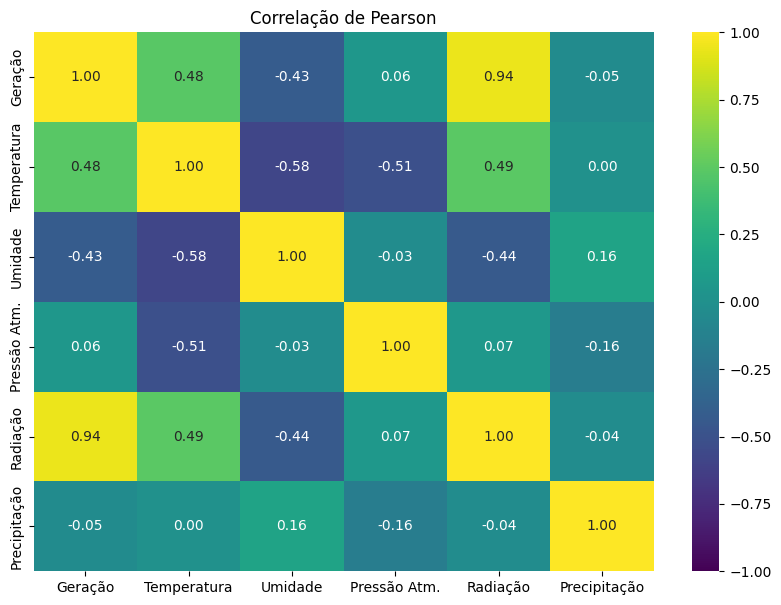

In [ ]:
nomes_heatmap = {
    'geracao_alvo_mwmed': 'Geração',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)': 'Temperatura',
    'UMIDADE RELATIVA DO AR, HORARIA(%)': 'Umidade',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)': 'Pressão Atm.',
    'Radiação (Wh/m2)': 'Radiação',
    'PRECIPITACAO ERA5, HORARIA(mm)': 'Precipitação'
}

corr = df_com_restricao[list(nomes_heatmap.keys())].corr()
corr = corr.rename(index=nomes_heatmap, columns=nomes_heatmap)

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='viridis',
    vmin=-1,
    vmax=1
)

plt.title('Correlação de Pearson')
plt.show()

In [ ]:
variaveis = [
    'geracao_alvo_mwmed',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)',
    'UMIDADE RELATIVA DO AR, HORARIA(%)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)',
    'Radiação (Wh/m2)',
    'PRECIPITACAO ERA5, HORARIA(mm)'
]

df_corr = df_com_restricao[variaveis].copy()

corr_pearson = df_corr.corr(method='pearson')
corr_spearman = df_corr.corr(method='spearman')

display(corr_pearson)
display(corr_spearman)

,geracao_alvo_mwmed,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
geracao_alvo_mwmed,1.000000,0.477106,-0.428323,0.059759,0.942859,-0.045174
"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",0.477106,1.000000,-0.584431,-0.509747,0.489610,0.003483
"UMIDADE RELATIVA DO AR, HORARIA(%)",-0.428323,-0.584431,1.000000,-0.034232,-0.440514,0.162964
"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",0.059759,-0.509747,-0.034232,1.000000,0.067955,-0.158451
Radiação (Wh/m2),0.942859,0.489610,-0.440514,0.067955,1.000000,-0.037635
"PRECIPITACAO ERA5, HORARIA(mm)",-0.045174,0.003483,0.162964,-0.158451,-0.037635,1.000000


,geracao_alvo_mwmed,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
geracao_alvo_mwmed,1.000000,0.490445,-0.415374,0.024314,0.965502,0.138420
"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",0.490445,1.000000,-0.586516,-0.471060,0.490372,0.168777
"UMIDADE RELATIVA DO AR, HORARIA(%)",-0.415374,-0.586516,1.000000,-0.055256,-0.408239,0.235034
"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",0.024314,-0.471060,-0.055256,1.000000,0.034117,-0.341879
Radiação (Wh/m2),0.965502,0.490372,-0.408239,0.034117,1.000000,0.156939
"PRECIPITACAO ERA5, HORARIA(mm)",0.138420,0.168777,0.235034,-0.341879,0.156939,1.000000


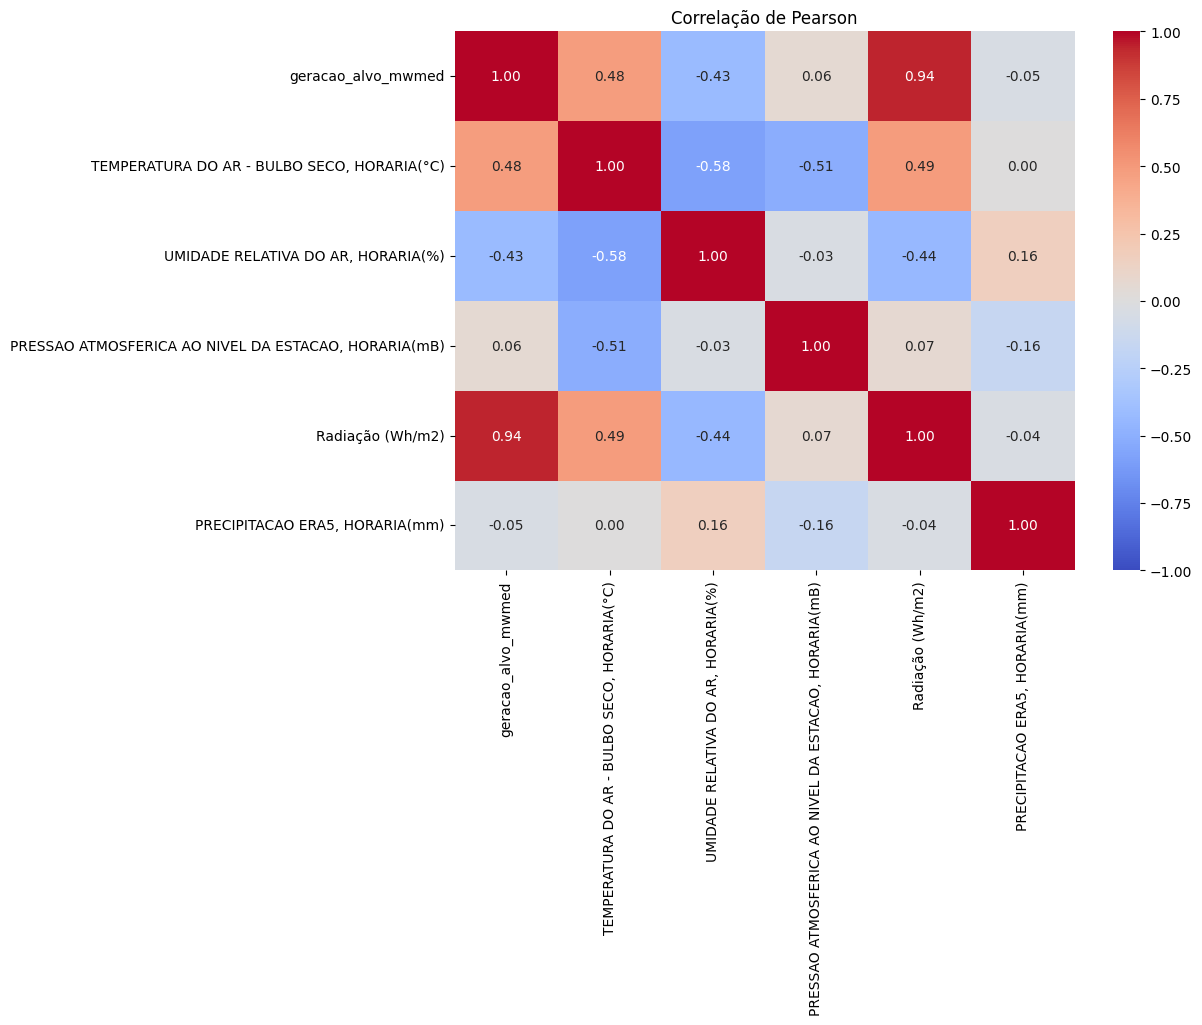

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlação de Pearson')
plt.show()

Geração
1.   Radiação
2.   Temperatura      

Pressão e Precipitação influenciam mas bem pouco. Na analise das correlações entre as variáveis, Precipitação foi a que menos representou relação com as demais features, com correlação máxima de 0.16


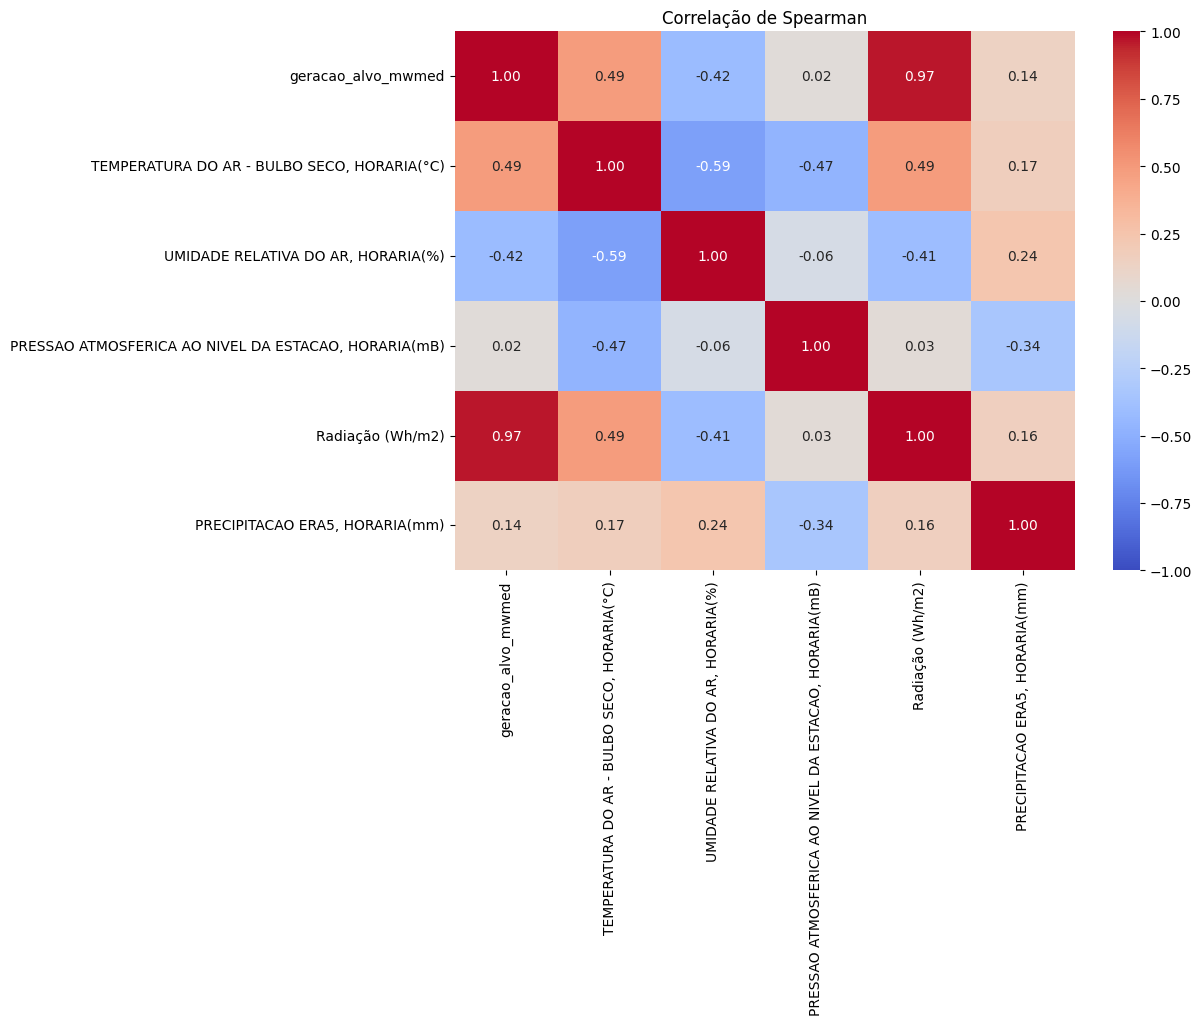

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlação de Spearman')
plt.show()

relação da precipitação com outras variáveis não é bem descrita por uma relação linear efeito da distribuição extremamente assimétrica e concentrada em zero

### Relação individuais

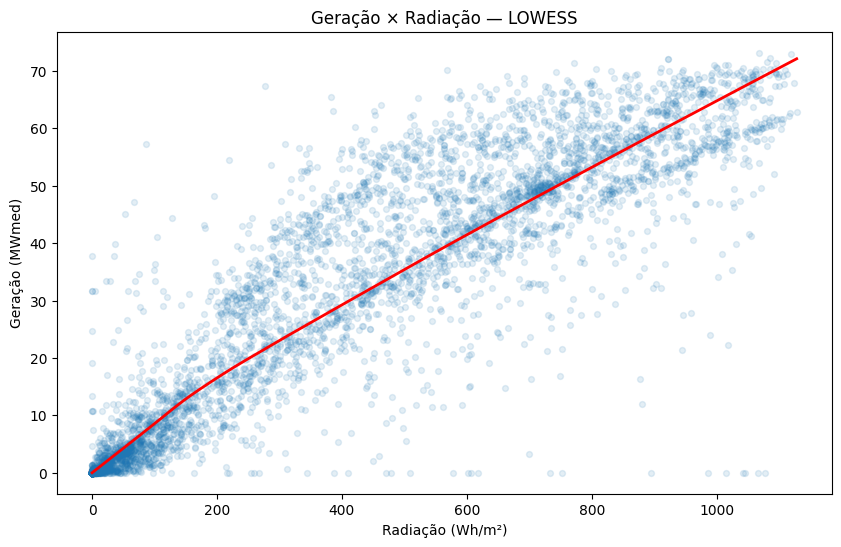

In [ ]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_com_restricao,
    x='Radiação (Wh/m2)',
    y='geracao_alvo_mwmed',
    lowess=True,
    scatter_kws={
        'alpha': 0.12,
        's': 18
    },
    line_kws={
        'color': 'red',
        'linewidth': 2
    }
)

plt.xlabel('Radiação (Wh/m²)')
plt.ylabel('Geração (MWmed)')
plt.title('Geração × Radiação — LOWESS')

plt.show()

O gráfico de dispersão entre radiação e geração confirma a forte associação positiva indicada pelas correlações. Entretanto, a dispersão dos pontos para um mesmo nível de radiação mostra que a geração não depende exclusivamente dessa variável, sendo também influenciada por outros fatores meteorológicos e temporais. Além disso, a forma da nuvem sugere uma relação crescente, porém não perfeitamente linear, com indícios de saturação em níveis mais altos de geração.

Radiação x Geração, próximo a uma tendência linear.

Temperatura muito associada ao ciclo diurno e à radiação.

Conforme a umidade aumenta a geração média tende a cair. Coeficiente de relação negativo.

## ACF da Geração

<Figure size 1200x500 with 0 Axes>

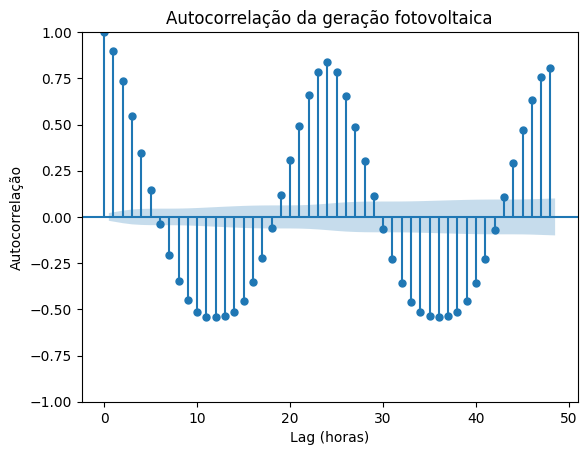

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

serie = (
    df_com_restricao
    .sort_values('data_hora_utc')
    .set_index('data_hora_utc')['geracao_alvo_mwmed']
)

plt.figure(figsize=(12, 5))

plot_acf(
    serie,
    lags=48,
    alpha=0.05
)

plt.title('Autocorrelação da geração fotovoltaica')
plt.xlabel('Lag (horas)')
plt.ylabel('Autocorrelação')

plt.show()

In [ ]:
for lag in [1, 2, 3, 24]:
    autocorr = serie.autocorr(lag=lag)
    print(f't-{lag}: {autocorr:.4f}')

t-1: 0.8969
t-2: 0.7344
t-3: 0.5470
t-24: 0.8408


In [ ]:
df_temp = df_com_restricao.copy()

df_temp['hora'] = df_temp['data_hora_utc'].dt.hour

geracao_por_hora = (
    df_temp
    .groupby('hora')['geracao_alvo_mwmed']
    .agg(['mean', 'median'])
)

geracao_por_hora

,mean,median
hora,,
0,0.003466,0.0000
1,0.003466,0.0000
2,0.003466,0.0000
3,0.000000,0.0000
4,0.000000,0.0000
5,0.000000,0.0000
6,0.000000,0.0000
7,0.119438,0.0000
8,0.123214,0.0000


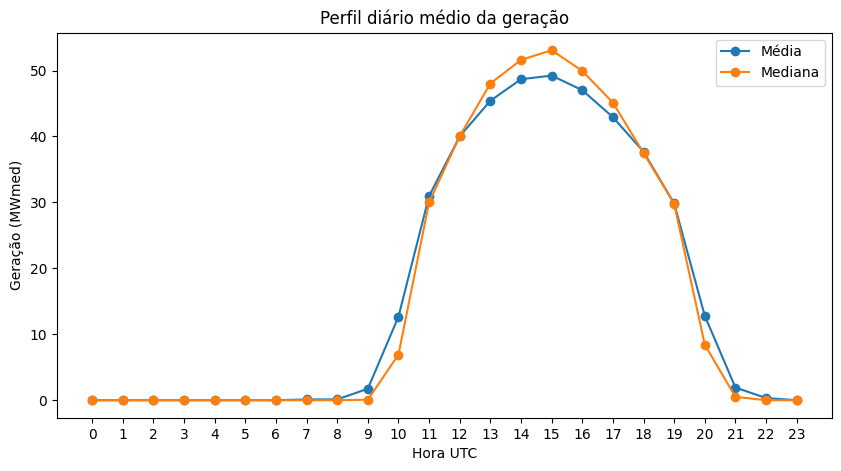

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    geracao_por_hora.index,
    geracao_por_hora['mean'],
    marker='o',
    label='Média'
)

plt.plot(
    geracao_por_hora.index,
    geracao_por_hora['median'],
    marker='o',
    label='Mediana'
)

plt.xticks(range(24))
plt.xlabel('Hora UTC')
plt.ylabel('Geração (MWmed)')
plt.title('Perfil diário médio da geração')
plt.legend()

plt.show()

In [ ]:
df_temp['mes'] = df_temp['data_hora_utc'].dt.month

geracao_por_mes = (
    df_temp
    .groupby('mes')['geracao_alvo_mwmed']
    .agg(['mean', 'median'])
)

geracao_por_mes

,mean,median
mes,,
1,21.305929,2.43275
2,19.269574,0.66150
3,19.902163,0.41550
4,13.282331,0.01850
5,14.181222,0.00000
6,11.672262,0.00000
7,14.494956,0.00000
8,15.299993,0.04600
9,17.555572,0.49050


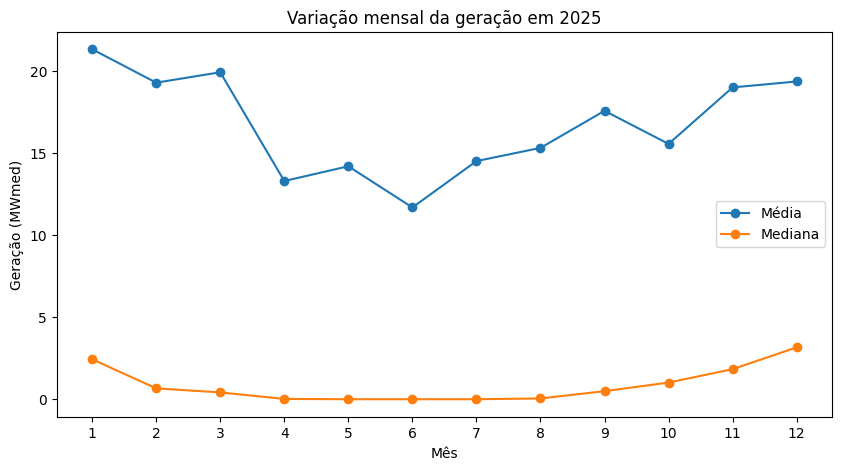

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    geracao_por_mes.index,
    geracao_por_mes['mean'],
    marker='o',
    label='Média'
)

plt.plot(
    geracao_por_mes.index,
    geracao_por_mes['median'],
    marker='o',
    label='Mediana'
)

plt.xticks(range(1, 13))
plt.xlabel('Mês')
plt.ylabel('Geração (MWmed)')
plt.title('Variação mensal da geração em 2025')
plt.legend()

plt.show()

In [ ]:
df_diurno = df_temp[
    df_temp['Radiação (Wh/m2)'] > 0
].copy()

geracao_diurna_mes = (
    df_diurno
    .groupby('mes')['geracao_alvo_mwmed']
    .agg(['mean', 'median'])
)

geracao_diurna_mes

,mean,median
mes,,
1,35.541730,40.92350
2,34.347017,36.91800
3,36.742098,43.32900
4,24.682606,20.88100
5,28.634315,32.98050
6,25.331198,28.04150
7,30.987922,33.04775
8,28.670553,31.72900
9,32.410286,38.05825


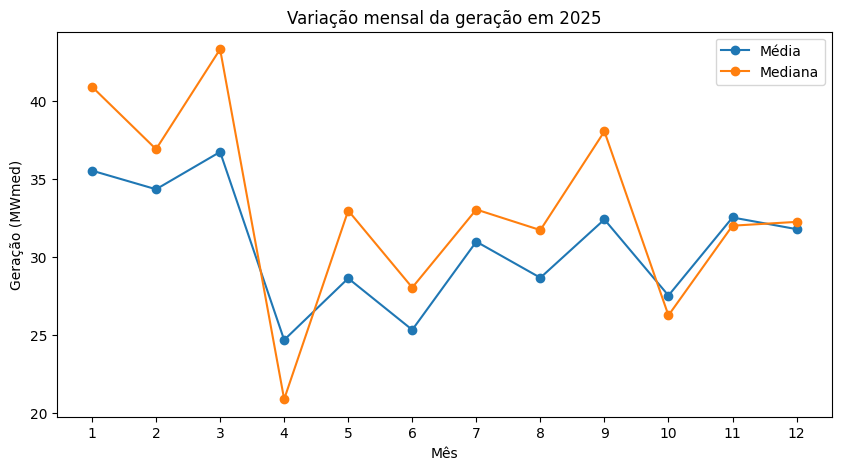

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    geracao_diurna_mes.index,
    geracao_diurna_mes['mean'],
    marker='o',
    label='Média'
)

plt.plot(
    geracao_diurna_mes.index,
    geracao_diurna_mes['median'],
    marker='o',
    label='Mediana'
)

plt.xticks(range(1, 13))
plt.xlabel('Mês')
plt.ylabel('Geração (MWmed)')
plt.title('Variação mensal da geração em 2025')
plt.legend()

plt.show()